# Devoir maison : Systèmes temps réel
## Semaines 1 et 2

**Nom :** Maram Ghribi   

Ce devoir reprend les notions de définition, classification, contraintes temporelles et analyse de systèmes temps réel.

## Objectifs
- Définir un système temps réel et expliquer la correction temporelle.
- Distinguer les systèmes temps réel strict, ferme et mou.
- Identifier capteurs, traitement, actionneurs et échéances.
- Calculer l'utilisation d'un processeur pour une tâche périodique.
- Analyser un ordonnancement simple et ses risques.

## Partie 1 : Définitions et classification

### 1. Définitions

1. **Système temps réel :** système informatique dont la correction dépend à la fois du résultat produit et du moment où il est produit.
2. Un résultat exact fourni trop tard peut être inutile ou dangereux : il ne respecte plus la contrainte temporelle et peut donc être considéré incorrect.
3. **Période (T) :** intervalle entre deux activations successives d'une tâche. **Temps d'exécution (C) :** durée CPU nécessaire à son traitement. **Échéance (D) :** instant limite auquel le traitement doit être terminé. **Latence :** délai entre un événement/entrée et la réponse du système.
4. Une contrainte stricte ne tolère pas le dépassement de l'échéance (résultat tardif invalide). Une contrainte non stricte peut tolérer un retard, selon ses conséquences.

### 2. Classification

| Système | Type | Conséquence d'un retard |
|---|---|---|
| Radar de détection | Strict | Détection tardive pouvant entraîner un danger. |
| Système ABS | Strict | Une réaction tardive peut compromettre le freinage. |
| Airbag | Strict | Un déclenchement tardif peut être inutile ou dangereux. |
| Lecture audio/vidéo | Mou | Retard : baisse de qualité, coupure ou décalage. |
| Supervision médicale | Ferme (selon l'alarme) | Une donnée tardive peut perdre son utilité; un retard peut être toléré ponctuellement. |
| Contrôle d'un réacteur chimique | Strict | Retard de contrôle pouvant entraîner un accident. |

**Justification :** l'ABS et l'airbag doivent réagir dans un délai très court pour assurer la sécurité, donc leurs échéances sont strictes. Pour la lecture audio/vidéo, un retard occasionnel peut provoquer une coupure sans rendre le système globalement inutilisable : c'est un temps réel mou.

## Partie 2 : Analyse fonctionnelle

| Système | Capteurs ou événements | Traitement | Actionneurs ou sortie | Échéance |
|---|---|---|---|---|
| Radar | Antenne, signal reçu | Détection et calcul de distance/vitesse | Affichage, alarme, commande | Avant la prochaine décision/détection utile |
| ABS | Capteurs de vitesse des roues | Détecter le blocage et moduler la pression | Modulateurs de pression/freinage | Quelques millisecondes, pendant le freinage |
| Airbag | Accéléromètres, capteurs de choc | Détecter collision et décider du déclenchement | Déploiement de l'airbag | Très court délai après collision |
| Décodage audio/vidéo | Flux audio/vidéo, paquets | Décodage et mise en tampon | Haut-parleur, écran | Avant le moment de lecture |
| Supervision médicale | ECG, pression, température, etc. | Analyse, détection d'anomalie | Alarme, affichage, notification | Rapidement en cas d'anomalie |
| Réacteur chimique | Température, pression, débit | Régulation et surveillance | Vannes, pompe, chauffage/refroidissement | Avant dépassement des limites de sécurité |

### Questions d'analyse

1. L'ABS, l'airbag et le contrôle du réacteur peuvent compromettre directement la sécurité si leur réponse est tardive. Le système médical peut également présenter un risque.
2. La lecture audio/vidéo peut accepter une dégradation progressive : perte de quelques images, variation de qualité ou léger retard.
3. Exemple : une charge élevée provoque un retard de décodage vidéo. Le système peut réduire la résolution ou supprimer des images pour préserver la fluidité.



## Partie 3 : Exercice de calcul

Données : Tâche 1 : C₁=2 ms, T₁=D₁=10 ms ; Tâche 2 : C₂=4 ms, T₂=D₂=20 ms.

1. Utilisation : U₁=C₁/T₁=2/10=**0,20 (20%)** ; U₂=C₂/T₂=4/20=**0,20 (20%)**.
2. Utilisation totale : U=U₁+U₂=0,20+0,20=**0,40 (40%)**.
3. En une seconde : tâche 1 : 1000/10=**100 instances** ; tâche 2 : 1000/20=**50 instances**.
4. Avec un ordonnancement préemptif EDF et des échéances égales aux périodes, les échéances sont respectées : charge 40% et chaque tâche peut terminer avant son échéance. Même en exécution sans préemption avec ces tâches, le calendrier simple reste faisable.
5. Condition suffisante Liu et Layland pour n=2 : 2(√2−1)≈**0,8284**. U=0,40≤0,8284, donc la condition est satisfaite.



## Partie 4 : Simulation Python

Le code représente les intervalles d'exécution d'une tâche périodique. Les tests `C=2,T=5`, `C=5,T=5` et `C=6,T=5` permettent de comparer le temps d'exécution à la période.

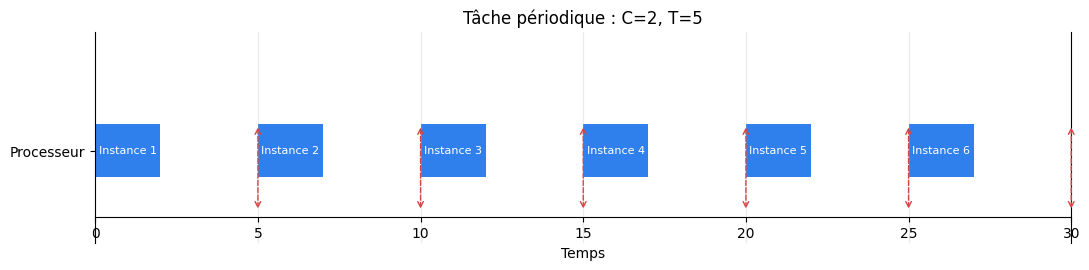

In [1]:
import matplotlib.pyplot as plt

# Paramètres à modifier
C = 2
T = 5
duree_simulation = 30

activations = list(range(0, duree_simulation, T))
fin_execution = [min(activation + C, duree_simulation) for activation in activations]

fig, ax = plt.subplots(figsize=(11, 2.8))
for numero, (activation, fin) in enumerate(zip(activations, fin_execution), 1):
    ax.barh(0.25, fin - activation, left=activation, height=0.2, color="#2f80ed")
    ax.text((activation + fin) / 2, 0.25, f"Instance {numero}", ha="center", va="center", color="white", fontsize=8)
    ax.annotate("", xy=(activation + T, 0.02), xytext=(activation + T, 0.35), arrowprops={"arrowstyle": "<->", "color": "#d64545", "linestyle": "--"})

ax.spines["bottom"].set_position(("data", 0))
ax.spines["top"].set_visible(False)
ax.set_xlim(0, duree_simulation)
ax.set_ylim(-0.1, 0.7)
ax.set_yticks([0.25])
ax.set_yticklabels(["Processeur"])
ax.set_xticks(range(0, duree_simulation + 1, T))
ax.set_xlabel("Temps")
ax.set_title(f"Tâche périodique : C={C}, T={T}")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Interprétation de la simulation

1. Si **C≤T**, chaque instance peut terminer avant sa prochaine échéance dans ce modèle simple.
2. Lorsque **C>T**, une instance n'a pas terminé avant l'arrivée de la suivante : les tâches s'accumulent et les échéances sont violées.
3. Lorsque **C=T**, la tâche utilise tout le processeur entre deux activations. Il n'y a aucune marge pour une autre tâche, une interruption ou une variation du temps d'exécution.

Ainsi, pour une tâche périodique seule, la condition C≤T est nécessaire pour respecter les échéances dans ce modèle.

## Synthèse finale

Un système temps réel doit produire un résultat correct dans le délai imposé. Il faut donc prendre en compte les échéances et la charge du processeur lors de la conception et de l'ordonnancement des tâches. Si la charge est trop élevée, des tâches risquent de terminer en retard. La nature du système détermine alors la gravité du retard : il peut être dangereux dans un système strict, rendre un résultat inutile dans un système ferme ou seulement dégrader la qualité dans un système mou. Une conception fiable doit prévoir une marge de calcul et un comportement adapté en cas de surcharge.

### Références
- Présentation `2-Concepts.pptx`.
- Notebook `STR_01_Introduction.ipynb`.
- Buttazzo, G. : *Hard Real-Time Computing Systems*.
- Liu, J. W. S. : *Real-Time Systems*.